1. Download do Dataset do repositório UCI

Download via urllib e descompactação para uso.

In [2]:
import urllib.request
import zipfile
import os
import pandas as pd

# URL direta do zip contendo o dataset no repositório UCI
url = "https://archive.ics.uci.edu/static/public/544/estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition.zip"
zip_path = "obesity_levels.zip"
extract_dir = "obesity_data"

print("Baixando o dataset...")
urllib.request.urlretrieve(url, zip_path)

print("Descompactando os arquivos...")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

# O zip principal contém outro zip interno com os dados
inner_zip = os.path.join(extract_dir, "ObesityDataSet_raw_and_data_sinthetic.zip")
if os.path.exists(inner_zip):
    with zipfile.ZipFile(inner_zip, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)

csv_path = os.path.join(extract_dir, "ObesityDataSet_raw_and_data_sinthetic.csv")
if os.path.exists(csv_path):
    df_real = pd.read_csv(csv_path)
    print("\nDataset carregado com sucesso!")
    print(f"Dimensões do dataset: {df_real.shape[0]} linhas e {df_real.shape[1]} colunas.")
    display(df_real.head())
else:
    print("Arquivo CSV não encontrado. Verifique a estrutura da pasta extraída:", os.listdir(extract_dir))

Baixando o dataset...
Descompactando os arquivos...

Dataset carregado com sucesso!
Dimensões do dataset: 2111 linhas e 17 colunas.


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


2. Preparação, Treinamento e Serialização do Modelo (Pipeline Offline)

Estrutura de diretórios, análise das amostras do nicho (Mulheres 40+), treino e criação do arquivo para uso na futura API.

In [ ]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Criação das pastas do projeto
os.makedirs("models", exist_ok=True)
os.makedirs("data", exist_ok=True)

# Quantidade de registros para Mulheres 40+ no dataset real
filtro_nicho = df_real[(df_real['Gender'] == 'Female') & (df_real['Age'] >= 40)]
print(f"Quantidade total de amostras no dataset: {df_real.shape[0]}")
print(f"Quantidade de amostras para o nicho (Mulheres 40+): {filtro_nicho.shape[0]}")

# Definindo features (X) e target (y)
X = df_real.drop(columns=['NObeyesdad'])
y = df_real['NObeyesdad']

# Identificar colunas numéricas e categóricas para o Pipeline
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X.select_dtypes(include=['object', 'string']).columns.tolist()

print(f"\nFeatures Numéricas ({len(numerical_cols)}): {numerical_cols}")
print(f"Features Categóricas ({len(categorical_cols)}): {categorical_cols}")

Quantidade total de amostras no dataset: 2111
Quantidade de amostras para o nicho (Mulheres 40+): 37

Features Numéricas (8): ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']
Features Categóricas (8): ['Gender', 'family_history_with_overweight', 'FAVC', 'CAEC', 'SMOKE', 'SCC', 'CALC', 'MTRANS']


In [10]:
# Divisão em Treino e Teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Construção do Pré-processamento
numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ])

# Criação do Pipeline Completo
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1))
])

# Treinamento do Modelo
print("Treinando o modelo RandomForest...")
model_pipeline.fit(X_train, y_train)

# Avaliação do Modelo
y_pred = model_pipeline.predict(X_test)
acuracia = accuracy_score(y_test, y_pred)

print(f"\nAcurácia do Modelo: {acuracia:.4f}\n")
print("Relatório de Classificação:")
print(classification_report(y_test, y_pred))

Treinando o modelo RandomForest...

Acurácia do Modelo: 0.9433

Relatório de Classificação:
                     precision    recall  f1-score   support

Insufficient_Weight       1.00      0.94      0.97        54
      Normal_Weight       0.79      0.93      0.86        58
     Obesity_Type_I       0.96      0.96      0.96        70
    Obesity_Type_II       1.00      0.98      0.99        60
   Obesity_Type_III       1.00      0.98      0.99        65
 Overweight_Level_I       0.91      0.86      0.88        58
Overweight_Level_II       0.96      0.93      0.95        58

           accuracy                           0.94       423
          macro avg       0.95      0.94      0.94       423
       weighted avg       0.95      0.94      0.94       423



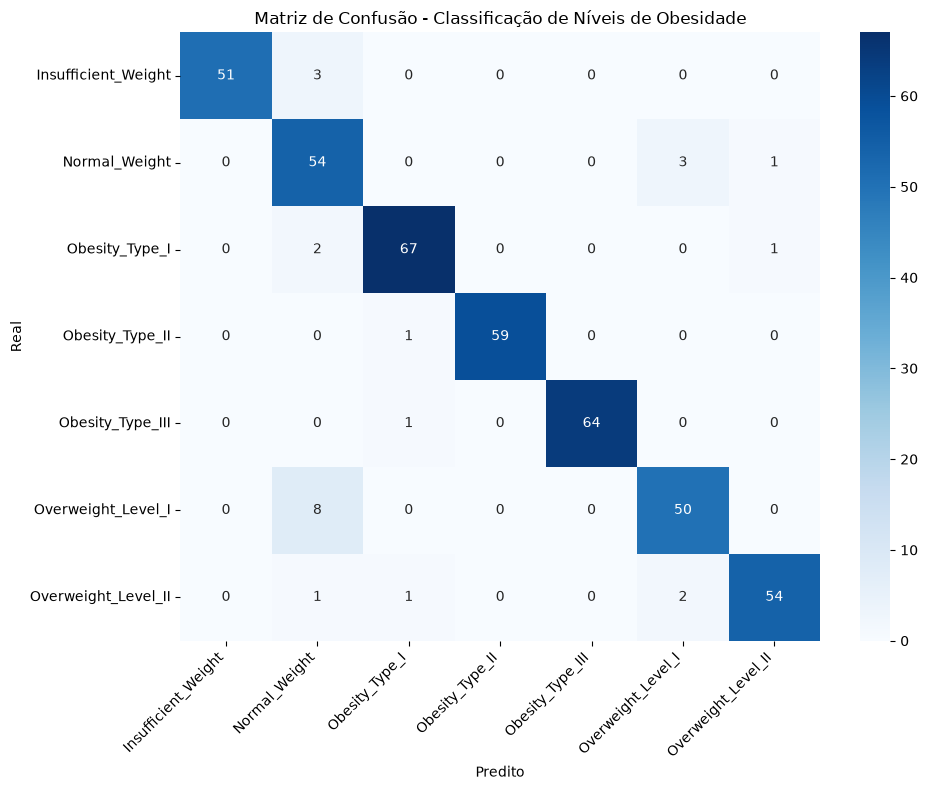

In [11]:
# Matriz de Confusão
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_test, y_pred, labels=model_pipeline.classes_)
sns.heatmap(cm, annot=True, fmt='d', xticklabels=model_pipeline.classes_, yticklabels=model_pipeline.classes_, cmap='Blues')
plt.title('Matriz de Confusão - Classificação de Níveis de Obesidade')
plt.xlabel('Predito')
plt.ylabel('Real')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [12]:
# Serialização do Artefato
model_path = "models/obesity_rf_pipeline.joblib"
joblib.dump(model_pipeline, model_path)
print(f"Pipeline de pré-processamento e modelo serializado com sucesso em: {model_path}")

Pipeline de pré-processamento e modelo serializado com sucesso em: models/obesity_rf_pipeline.joblib


3. Estrutura Modular da API FastAPI

In [13]:
# Criação do arquivo schemas.py
schemas_code = """from pydantic import BaseModel, Field
from typing import Optional

class PredictInputSchema(BaseModel):
    Gender: str = Field(..., description="Gênero do indivíduo (Female ou Male)", example="Female")
    Age: float = Field(..., description="Idade em anos", ge=0, le=120, example=45.0)
    Height: float = Field(..., description="Altura em metros", ge=0.5, le=2.5, example=1.65)
    Weight: float = Field(..., description="Peso em quilogramas", ge=10.0, le=300.0, example=68.0)
    family_history_with_overweight: str = Field(..., description="Histórico familiar de sobrepeso (yes ou no)", example="yes")
    FAVC: str = Field(..., description="Consumo frequente de alimentos de alto teor calórico (yes ou no)", example="no")
    FCVC: float = Field(..., description="Frequência de consumo de vegetais (normalmente de 1 a 3)", ge=1.0, le=3.0, example=2.0)
    NCP: float = Field(..., description="Número de refeições principais por dia", ge=1.0, le=4.0, example=3.0)
    CAEC: str = Field(..., description="Consumo de comida entre as refeições (no, Sometimes, Frequently, Always)", example="Sometimes")
    SMOKE: str = Field(..., description="Se o paciente fuma (yes ou no)", example="no")
    CH2O: float = Field(..., description="Consumo diário de água em litros", ge=1.0, le=3.0, example=2.0)
    SCC: str = Field(..., description="Monitoramento do consumo de calorias (yes ou no)", example="no")
    FAF: float = Field(..., description="Frequência de atividade física por semana (0 a 3)", ge=0.0, le=3.0, example=1.0)
    TUE: float = Field(..., description="Tempo de uso de dispositivos eletrônicos por dia (0 a 2)", ge=0.0, le=2.0, example=1.0)
    CALC: str = Field(..., description="Consumo de álcool (no, Sometimes, Frequently, Always)", example="Sometimes")
    MTRANS: str = Field(..., description="Meio de transporte utilizado", example="Public_Transportation")

class PredictOutputSchema(BaseModel):
    prediction: str = Field(..., description="Classe predita de nível de obesidade")
    status: str = Field("success", description="Status da requisição")
"""

with open("schemas.py", "w", encoding="utf-8") as f:
    f.write(schemas_code)
print("Arquivo 'schemas.py' criado com sucesso!")

Arquivo 'schemas.py' criado com sucesso!


In [14]:
# Criação do arquivo services.py
services_code = """import joblib
import pandas as pd
import os
from schemas import PredictInputSchema

class PredictionService:
    def __init__(self, model_path: str = "models/obesity_rf_pipeline.joblib"):
        if not os.path.exists(model_path):
            raise FileNotFoundError(f"Modelo não encontrado no caminho: {model_path}")
        self.pipeline = joblib.load(model_path)

    def predict(self, input_data: PredictInputSchema) -> str:
        # Converter os dados de entrada do Pydantic em um DataFrame para o Pipeline
        data_dict = input_data.model_dump()
        df = pd.DataFrame([data_dict])

        # Executar a inferência através do Pipeline do Scikit-Learn
        prediction = self.pipeline.predict(df)[0]
        return prediction
"""

with open("services.py", "w", encoding="utf-8") as f:
    f.write(services_code)
print("Arquivo 'services.py' criado com sucesso!")

Arquivo 'services.py' criado com sucesso!


In [15]:
# Criação do arquivo routers.py
routers_code = """from fastapi import APIRouter, HTTPException
from schemas import PredictInputSchema, PredictOutputSchema
from services import PredictionService

router = APIRouter(prefix="/api/v1", tags=["Obesity Prediction"])
try:
    # Inicializa o serviço carregando o pipeline serializado
    prediction_service = PredictionService()
except FileNotFoundError as e:
    # Se o script for inicializado sem o arquivo de modelo gerado
    prediction_service = None
    print("Aviso: Modelo serializado não encontrado. Por favor, treine e salve o modelo antes de subir a API.")

@router.post("/predict", response_model=PredictOutputSchema)
def predict_obesity(payload: PredictInputSchema):
    if prediction_service is None:
        raise HTTPException(status_code=503, detail="Serviço de predição indisponível devido à ausência do modelo.")

    try:
        prediction_result = prediction_service.predict(payload)
        return PredictOutputSchema(prediction=prediction_result, status="success")
    except Exception as e:
        raise HTTPException(status_code=500, detail=f"Erro interno ao processar predição: {str(e)}")

@router.get("/health")
def health_check():
    return {"status": "ok", "model_loaded": prediction_service is not None}
"""

with open("routers.py", "w", encoding="utf-8") as f:
    f.write(routers_code)
print("Arquivo 'routers.py' criado com sucesso!")

Arquivo 'routers.py' criado com sucesso!


In [16]:
# Criação do arquivo main.py
main_code = """from fastapi import FastAPI
from routers import router as api_router

app = FastAPI(
    title="API de Classificação de Níveis de Obesidade",
    description="API modular construída para o projeto prático final, focada na predição de níveis de obesidade.",
    version="1.0.0"
)

# Inclui as rotas desenvolvidas de forma modular
app.include_router(api_router)

@app.get("/")
def root():
    return {
        "message": "API para Predição e Classificação de Obesidade ativa.",
        "documentation": "/docs"
    }
"""

with open("main.py", "w", encoding="utf-8") as f:
    f.write(main_code)
print("Arquivo 'main.py' criado com sucesso!")

Arquivo 'main.py' criado com sucesso!


4. Otimização do Ciclo de Vida da API (Lifespan)

In [17]:
# Sobreescrevendo routers.py 
routers_code = """from fastapi import APIRouter, HTTPException, Request
from schemas import PredictInputSchema, PredictOutputSchema
import pandas as pd

router = APIRouter(prefix="/api/v1", tags=["Obesity Prediction"])

@router.post("/predict", response_model=PredictOutputSchema)
def predict_obesity(payload: PredictInputSchema, request: Request):
    # Obtendo o pipeline que foi pré-carregado no estado global da aplicação durante a inicialização (Lifespan)
    model_pipeline = getattr(request.app.state, "model_pipeline", None)

    if model_pipeline is None:
        raise HTTPException(
            status_code=503,
            detail="O modelo de predição não foi carregado corretamente na memória RAM da aplicação."
        )

    try:
        # Conversão direta do input Pydantic para DataFrame
        data_dict = payload.model_dump()
        df = pd.DataFrame([data_dict])
        prediction_result = model_pipeline.predict(df)[0]

        return PredictOutputSchema(prediction=prediction_result, status="success")
    except Exception as e:
        raise HTTPException(status_code=500, detail=f"Erro interno na inferência: {str(e)}")

@router.get("/health")
def health_check(request: Request):
    model_loaded = getattr(request.app.state, "model_pipeline", None) is not None
    return {"status": "ok", "model_loaded": model_loaded}
"""

with open("routers.py", "w", encoding="utf-8") as f:
    f.write(routers_code)
print("Arquivo 'routers.py' otimizado com sucesso!")

Arquivo 'routers.py' otimizado com sucesso!


In [18]:
# Sobreescrevendo main.py para configurar o lifespan e carregar o modelo na RAM uma única vez
main_code = """from fastapi import FastAPI
from contextlib import asynccontextmanager
import joblib
import os
from routers import router as api_router

# Definição do Lifespan Manager
@asynccontextmanager
async def lifespan(app: FastAPI):
    # Código executado durante a INICIALIZAÇÃO da aplicação
    model_path = "models/obesity_rf_pipeline.joblib"
    print(f"[Lifespan] Inicializando API e carregando modelo de {model_path} na RAM...")

    if os.path.exists(model_path):
        # Carrega uma única vez na RAM e associa ao estado global do app
        app.state.model_pipeline = joblib.load(model_path)
        print("[Lifespan] Modelo carregado com sucesso na memória!")
    else:
        print("[Lifespan] CRÍTICO: Arquivo de modelo serializado não encontrado!")
        app.state.model_pipeline = None

    yield # A aplicação fica ativa respondendo requisições HTTP

    # Código executado quando a aplicação é ENCERRADA
    print("[Lifespan] Encerrando API e limpando recursos...")
    if hasattr(app.state, "model_pipeline"):
        del app.state.model_pipeline

# Inicialização do FastAPI com lifespan
app = FastAPI(
    title="API de Classificação de Níveis de Obesidade",
    description="API otimizada com ciclo de vida (lifespan) garantindo leitura única de modelo na RAM.",
    version="1.1.0",
    lifespan=lifespan
)

app.include_router(api_router)

@app.get("/")
def root():
    return {
        "message": "API para Predição e Classificação de Obesidade ativa.",
        "documentation": "/docs"
    }
"""

with open("main.py", "w", encoding="utf-8") as f:
    f.write(main_code)
print("Arquivo 'main.py' otimizado com sucesso!")

Arquivo 'main.py' otimizado com sucesso!


5. Teste de Validação Estrita com Pydantic

Demonstração de que os dados fora do padrão estipulado em schemas.py são interceptados de imediato, garantindo que o modelo nunca receba lixo de entrada.

In [20]:
from pydantic import ValidationError
from schemas import PredictInputSchema

# Exemplo 1: Dados válidos de acordo com o esquema
dados_validos = {
    "Gender": "Female",
    "Age": 45.0,
    "Height": 1.65,
    "Weight": 68.0,
    "family_history_with_overweight": "yes",
    "FAVC": "no",
    "FCVC": 2.0,
    "NCP": 3.0,
    "CAEC": "Sometimes",
    "SMOKE": "no",
    "CH2O": 2.0,
    "SCC": "no",
    "FAF": 1.0,
    "TUE": 1.0,
    "CALC": "Sometimes",
    "MTRANS": "Public_Transportation"
}

try:
    validated_instance = PredictInputSchema(**dados_validos)
    print("✅ Exemplo 1: Dados válidos processados com sucesso!")
    print("Representação do objeto:", validated_instance.model_dump())
except ValidationError as e:
    print("❌ Falha inesperada:", e.json())

print("-" * 80)

# Exemplo 2: Dados inválidos (Idade negativa e peso inválido do tipo string)
dados_invalidos = dados_validos.copy()
dados_invalidos["Age"] = -5.0       # Erro: Violência da regra ge=0
dados_invalidos["Weight"] = "muito"  # Erro: Tipo inválido (deveria ser float)

try:
    PredictInputSchema(**dados_invalidos)
    print("❌ Exemplo 2: Dados inválidos passaram sem validação (ERRO!)")
except ValidationError as e:
    print("✅ Exemplo 2: Interceptado perfeitamente pelo Pydantic (Erro de validação detectado)!")
    print(e)

✅ Exemplo 1: Dados válidos processados com sucesso!
Representação do objeto: {'Gender': 'Female', 'Age': 45.0, 'Height': 1.65, 'Weight': 68.0, 'family_history_with_overweight': 'yes', 'FAVC': 'no', 'FCVC': 2.0, 'NCP': 3.0, 'CAEC': 'Sometimes', 'SMOKE': 'no', 'CH2O': 2.0, 'SCC': 'no', 'FAF': 1.0, 'TUE': 1.0, 'CALC': 'Sometimes', 'MTRANS': 'Public_Transportation'}
--------------------------------------------------------------------------------
✅ Exemplo 2: Interceptado perfeitamente pelo Pydantic (Erro de validação detectado)!
2 validation errors for PredictInputSchema
Age
  Input should be greater than or equal to 0 [type=greater_than_equal, input_value=-5.0, input_type=float]
    For further information visit https://errors.pydantic.dev/2.14/v/greater_than_equal
Weight
  Input should be a valid number, unable to parse string as a number [type=float_parsing, input_value='muito', input_type=str]
    For further information visit https://errors.pydantic.dev/2.14/v/float_parsing


5. 1. Correção dos Erros de Validação (Ajustando os Dados de Teste)
Ajuste dos valores incorretos (Age: -5.0 e Weight: 'muito') para dados válidos que respeitam as regras do Pydantic (Age >= 0 e Weight como um número decimal).

In [21]:
from schemas import PredictInputSchema

# Corrigindo os dados inserindo valores aceitáveis e do tipo correto
dados_corrigidos = {
    "Gender": "Female",
    "Age": 45.0,                         # Corrigido: maior ou igual a 0
    "Height": 1.65,
    "Weight": 68.0,                       # Corrigido: string 'muito' substituída por float válido
    "family_history_with_overweight": "yes",
    "FAVC": "no",
    "FCVC": 2.0,
    "NCP": 3.0,
    "CAEC": "Sometimes",
    "SMOKE": "no",
    "CH2O": 2.0,
    "SCC": "no",
    "FAF": 1.0,
    "TUE": 1.0,
    "CALC": "Sometimes",
    "MTRANS": "Public_Transportation"
}

try:
    # Nova tentativa de validação com os dados corrigidos
    objeto_validado = PredictInputSchema(**dados_corrigidos)
    print("✅ Dados corrigidos com sucesso! Nenhuma inconsistência encontrada pelo Pydantic.")
    print("Payload validado:", objeto_validado.model_dump())
except Exception as e:
    print("❌ Erro de validação:", e)

✅ Dados corrigidos com sucesso! Nenhuma inconsistência encontrada pelo Pydantic.
Payload validado: {'Gender': 'Female', 'Age': 45.0, 'Height': 1.65, 'Weight': 68.0, 'family_history_with_overweight': 'yes', 'FAVC': 'no', 'FCVC': 2.0, 'NCP': 3.0, 'CAEC': 'Sometimes', 'SMOKE': 'no', 'CH2O': 2.0, 'SCC': 'no', 'FAF': 1.0, 'TUE': 1.0, 'CALC': 'Sometimes', 'MTRANS': 'Public_Transportation'}


6. Testes de Integração e Validação dos Endpoints com FastAPI TestClient
Demonstrando o uso do TestClient para simular requisições HTTP reais nos endpoints /api/v1/health e /api/v1/predict. 

In [25]:
import importlib
import sys
from fastapi.testclient import TestClient

# Recarregar os arquivos do disco
for modulo in ['schemas', 'services', 'routers', 'main']:
    if modulo in sys.modules:
        importlib.reload(sys.modules[modulo])

# Importar a instância atualizada do app após o reload
from main import app

# Executar os testes garantindo o disparo do 'lifespan' usando o gerenciador de contexto
with TestClient(app) as client:

    print("=== 1. Testando o Endpoint de Monitoramento (GET /api/v1/health) ===")
    response_health = client.get("/api/v1/health")
    print(f"Status Code: {response_health.status_code}")
    print(f"Response JSON: {response_health.json()}")
    assert response_health.status_code == 200
    assert response_health.json()["status"] == "ok"
    assert response_health.json()["model_loaded"] is True

    print("\n" + "="*60 + "\n")

    print("=== 2. Testando o Endpoint de Inferência com Dados Válidos (POST /api/v1/predict) ===")
    payload_valido = {
        "Gender": "Female",
        "Age": 45.0,
        "Height": 1.65,
        "Weight": 68.0,
        "family_history_with_overweight": "yes",
        "FAVC": "no",
        "FCVC": 2.0,
        "NCP": 3.0,
        "CAEC": "Sometimes",
        "SMOKE": "no",
        "CH2O": 2.0,
        "SCC": "no",
        "FAF": 1.0,
        "TUE": 1.0,
        "CALC": "Sometimes",
        "MTRANS": "Public_Transportation"
    }

    response_predict = client.post("/api/v1/predict", json=payload_valido)
    print(f"Status Code: {response_predict.status_code}")
    print(f"Response JSON: {response_predict.json()}")
    assert response_predict.status_code == 200
    assert "prediction" in response_predict.json()
    assert response_predict.json()["status"] == "success"

    print("\n" + "="*60 + "\n")

    print("=== 3. Testando o Tratamento de Erros de Validação (Payload Inválido - HTTP 422) ===")
    payload_invalido = payload_valido.copy()
    payload_invalido["Age"] = -50.0  # Idade fora do intervalo permitido [0, 120]
    payload_invalido["Weight"] = "string_invalida"  # Tipo inválido

    response_invalid = client.post("/api/v1/predict", json=payload_invalido)
    print(f"Status Code: {response_invalid.status_code} (Unprocessable Entity)")
    print("Primeiro erro retornado no JSON:")
    print(response_invalid.json()["detail"][0])
    assert response_invalid.status_code == 422

[Lifespan] Inicializando API e carregando modelo de models/obesity_rf_pipeline.joblib na RAM...
[Lifespan] Modelo carregado com sucesso na memória!
=== 1. Testando o Endpoint de Monitoramento (GET /api/v1/health) ===
Status Code: 200
Response JSON: {'status': 'ok', 'model_loaded': True}


=== 2. Testando o Endpoint de Inferência com Dados Válidos (POST /api/v1/predict) ===
Status Code: 200
Response JSON: {'prediction': 'Overweight_Level_II', 'status': 'success'}


=== 3. Testando o Tratamento de Erros de Validação (Payload Inválido - HTTP 422) ===
Status Code: 422 (Unprocessable Entity)
Primeiro erro retornado no JSON:
{'type': 'greater_than_equal', 'loc': ['body', 'Age'], 'msg': 'Input should be greater than or equal to 0', 'input': -50.0, 'ctx': {'ge': 0.0}}
[Lifespan] Encerrando API e limpando recursos...
